# Mammal Sleep Patterns

How does recorded sleep differ by feeding category?

Data: [ggplot2/msleep](https://vincentarelbundock.github.io/Rdatasets/doc/ggplot2/msleep.html)

This notebook performs a descriptive analysis on a real historical dataset. Source limitations: Species are not independent random samples; missing feeding labels are excluded.

In [1]:
from pathlib import Path
from analysis import run
result = run(Path.cwd())
result["manifest"]

Out[0]: 
{'project': 'Mammal Sleep Patterns',
 'executed_utc': '2026-11-21T10:14:10.303413+00:00',
 'source': 'https://vincentarelbundock.github.io/Rdatasets/csv/ggplot2/msleep.csv',
 'documentation': 'https://vincentarelbundock.github.io/Rdatasets/doc/ggplot2/msleep.html',
 'sha256': 'bc8b9ff24accf5c1211e89bc0b7a06d42c98347488867d890cade5be4b437b89',
 'raw_rows': 83,
 'analysis_rows': 76,
 'excluded_rows': 7,
 'exact_duplicate_rows': 0,
 'duplicates_policy': 'Retained; duplicate values do not necessarily mean duplicate entities.',
 'python': '3.12.14',
 'pandas': '2.2.3',
 'numpy': '2.3.5',
 'matplotlib': '3.10.8'}


## Data quality
Missing required variables are excluded, not silently imputed. Repeated rows are preserved; review the source observation grain.

In [2]:
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv("outputs/quality_audit.csv"))

,column,dtype,missing,missing_pct,distinct
0,rownames,int64,0,0.000000,83
1,name,object,0,0.000000,83
2,genus,object,0,0.000000,77
3,vore,object,7,8.433735,4
4,order,object,0,0.000000,19
5,conservation,object,29,34.939759,6
6,sleep_total,float64,0,0.000000,65
7,sleep_rem,float64,22,26.506024,32
8,sleep_cycle,float64,51,61.445783,22
9,awake,float64,0,0.000000,65


## SQL and analysis
Complete-case descriptive comparison of sleep_total by vore; show group counts, mean, minimum and maximum.

In [3]:
print(Path("analysis.sql").read_text())
display(result["table"].head(30))
print(result["finding"])

SELECT "vore" AS segment, COUNT(*) AS rows_used, AVG("sleep_total") AS metric, MIN("sleep_total") AS minimum, MAX("sleep_total") AS maximum FROM observations GROUP BY "vore" ORDER BY "vore";

The largest observed mean sleep_total is 14.940 for insecti. This ranking is descriptive, not a recommendation.


,segment,rows_used,metric,minimum,maximum
0,carni,19,10.378947,2.7,19.4
1,herbi,32,9.509375,1.9,16.6
2,insecti,5,14.940000,8.4,19.9
3,omni,20,10.925000,8.0,18.0


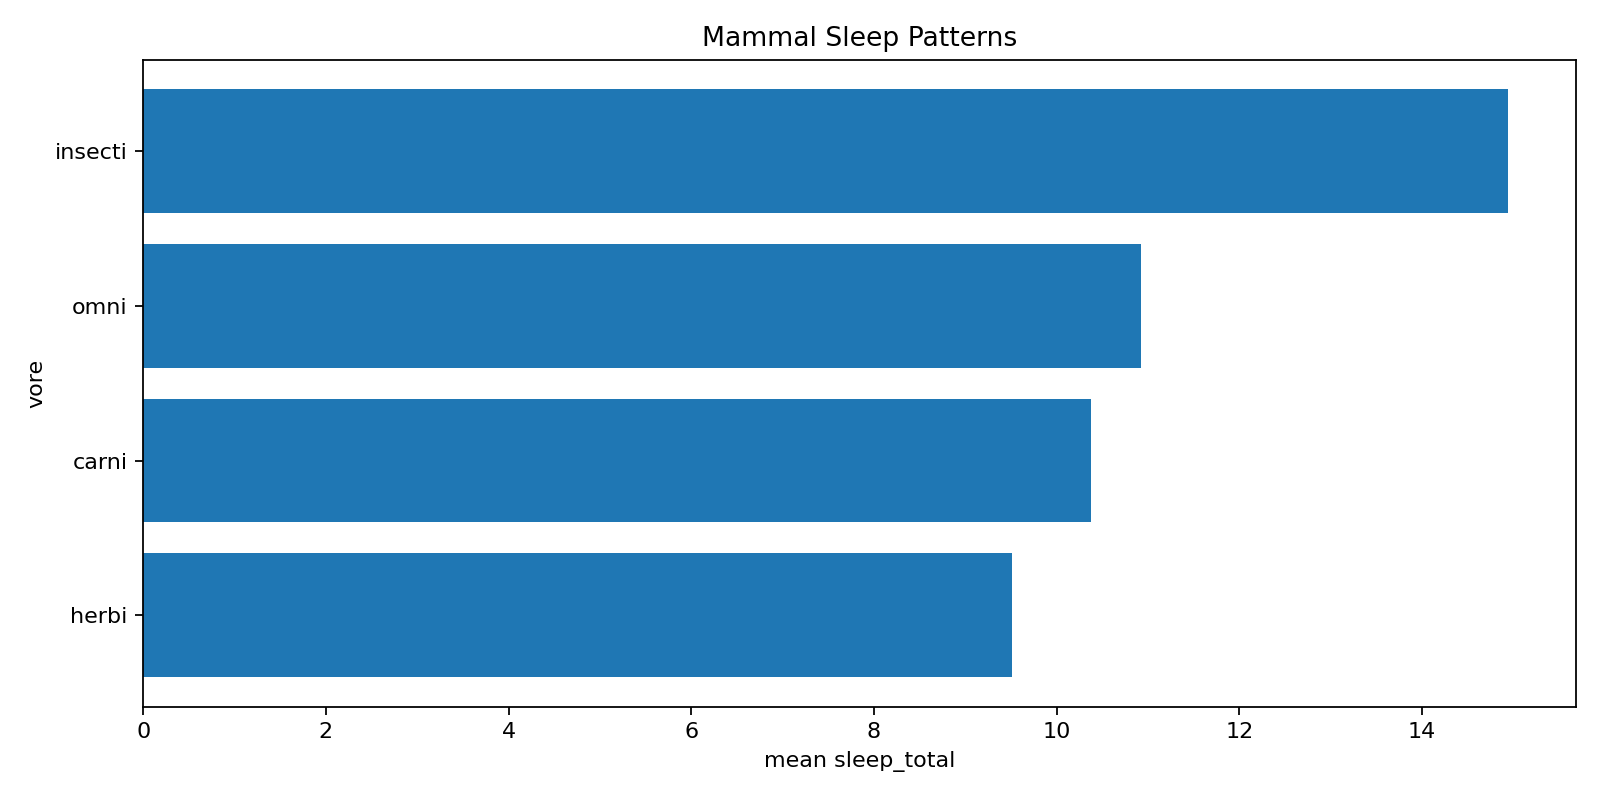

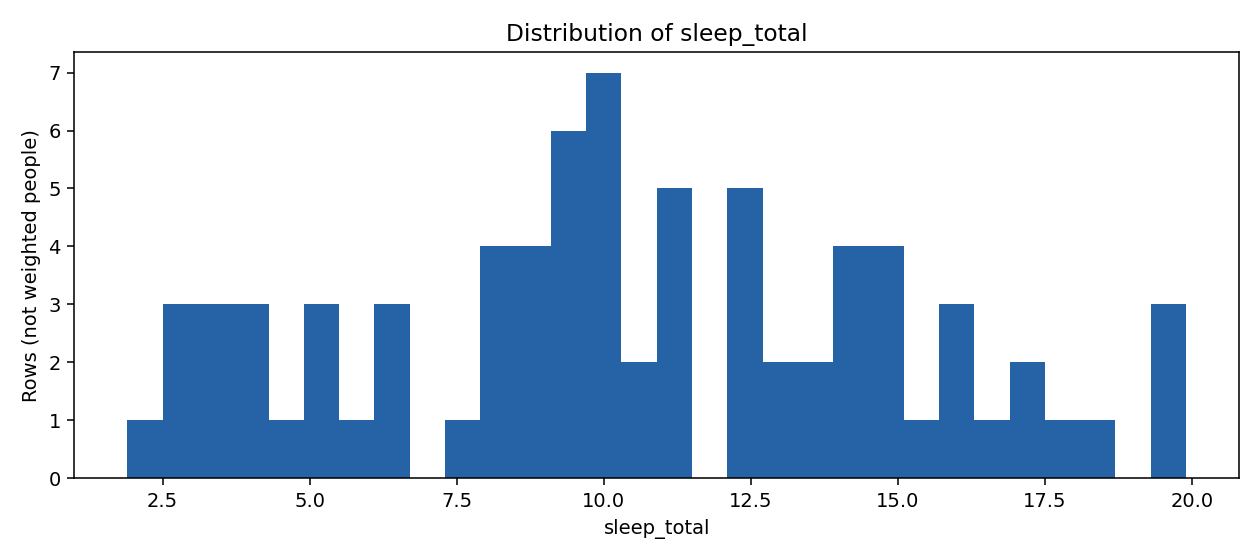

In [4]:
display(Image(filename="outputs/main_chart.png"))
display(Image(filename="outputs/distribution.png"))

## Interpretation
Species are not independent random samples; missing feeding labels are excluded.

**Next action:** Check sample sizes and phylogenetic dependence before scientific inference.

Read outputs/REPORT.md for executed findings. This project does not establish causation or a production decision rule.